In [1]:
import pandas as pd
import scanpy as sc
import sys
from pathlib import Path
import numpy as np

In [2]:
# Add the IDEAS repo root to Python's import path
repo_root = Path("/home/csb/Saloni/IDEAS_ID/IDEAS")
sys.path.append(str(repo_root))

from computeID.functions_IDEAS import compute_ID

/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
adata = sc.read('/home/csb/Saloni/IDEAS_ID/IDEAS/Data/MCF10A_dose.h5ad')

In [4]:
print(adata)

AnnData object with n_obs × n_vars = 8882 × 33694
    obs: 'GBC_annot', 'Values', 'Dose_pM'


In [5]:
id_local = compute_ID(
    adata,
    group="all",
    method="local_2nn",
    n_neighbors=50,
    normalization=True,
    full_output=True,
    id_score=True
)

print(id_local.shape)

Computing Intrinsic Dimension:   0%|          | 0/1 [00:00<?, ?it/s]

Computing ID:


Computing Intrinsic Dimension: 100%|██████████| 1/1 [01:00<00:00, 60.66s/it]

(8882, 1)


In [6]:
id_results = compute_ID(
    adata,
    group="Dose_pM",
    method="2nn",
    n_samples=30,
    sample_size=0,
    normalization=True,
    full_output=True,
    id_score=True
)

/home/csb/Saloni/IDEAS_ID/IDEAS/computeID/functions_IDEAS.py:41: UserWarning: 'sample_size' not specified: automatically set to 689 (80% of smallest group size: 8882)
  warnings.warn(f"'sample_size' not specified: automatically set to {sample_size} (80% of smallest group size: {n_obs})")
Computing Intrinsic Dimension:   0%|          | 0/8 [00:00<?, ?it/s]

Computing ID for Dose_pM 0.0:


Computing Intrinsic Dimension:  12%|█▎        | 1/8 [00:06<00:45,  6.50s/it]

Computing ID for Dose_pM 12.5:


Computing Intrinsic Dimension:  25%|██▌       | 2/8 [00:13<00:39,  6.54s/it]

...

Computing Intrinsic Dimension:  75%|███████▌  | 6/8 [00:39<00:13,  6.57s/it]

Computing ID for Dose_pM 400.0:


Computing Intrinsic Dimension:  88%|████████▊ | 7/8 [00:46<00:06,  6.60s/it]

Computing ID for Dose_pM 800.0:


Computing Intrinsic Dimension: 100%|██████████| 8/8 [00:52<00:00,  6.59s/it]


In [ ]:
print(id_results.shape)
display(id_results.head())

print(id_local.shape)
print(id_local.head())

(30, 8)


,0.0,12.5,25.0,50.0,100.0,200.0,400.0,800.0
1,0.084422,0.279815,0.209254,0.650770,0.482595,0.669160,0.855735,0.616918
2,0.425157,0.317553,0.249334,0.955009,0.569978,0.819154,0.735173,0.560431
3,0.207831,0.283889,0.013075,0.735117,0.669870,0.812502,0.755778,0.791604
4,0.422074,0.527842,0.186548,0.677831,0.473526,0.869917,0.578501,0.402534
5,0.333747,0.336238,0.424276,0.655844,0.517089,0.475772,0.582033,0.510874


In [7]:
id_summary = pd.DataFrame({
    "Dose_pM": id_results.columns,
    "ID": id_results.mean(axis=0),
    "SD": id_results.std(axis=0)
})

display(id_summary)

id_local_df = id_local.copy()

id_local_df.index.name = "cell"

id_local_df.to_excel(
    "/home/csb/Saloni/SCENT/data/ID/MCF10A_Dose_ID_local.xlsx"
)

print(id_local_df.head())

,Dose_pM,ID,SD
0.0,0.0,0.254660,0.100915
12.5,12.5,0.363720,0.107131
25.0,25.0,0.211808,0.107190
50.0,50.0,0.694012,0.118416
100.0,100.0,0.468484,0.144250
200.0,200.0,0.558069,0.121524
400.0,400.0,0.656899,0.091776
800.0,800.0,0.565269,0.103541


                          ID
AAACCTGAGAAAGTGG-1  0.335918
AAACCTGAGATCACGG-1  0.369625
AAACCTGAGCTCCTCT-1  0.338579
AAACCTGAGCTGCAAG-1  0.210675
AAACCTGAGGCCCTTG-1  0.543920


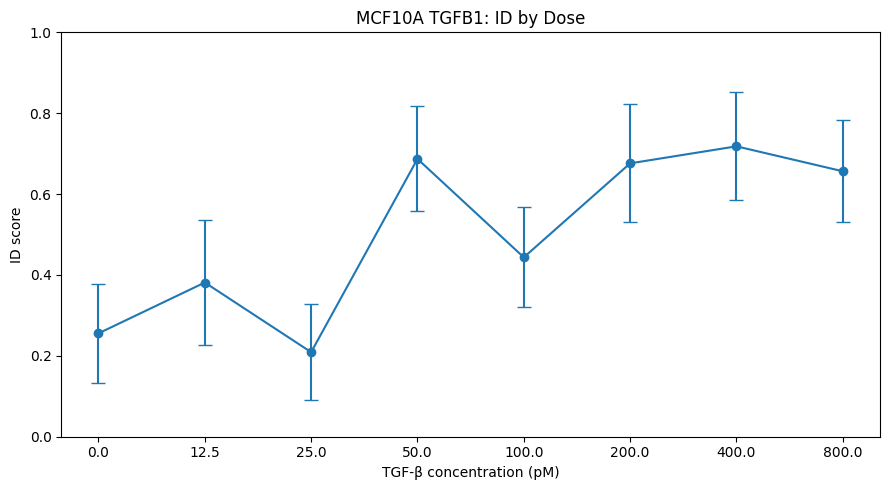

In [8]:
import matplotlib.pyplot as plt

doses = id_summary["Dose_pM"].astype(str)

plt.figure(figsize=(9, 5))

plt.errorbar(
    range(len(id_summary)),
    id_summary["ID"],
    yerr=id_summary["SD"],
    fmt="o-",
    capsize=5
)

plt.xticks(
    range(len(id_summary)),
    doses
)

plt.xlabel("TGF-β concentration (pM)")
plt.ylabel("ID score")
plt.ylim(0, 1)
plt.title("MCF10A TGFB1: ID by Dose")

plt.tight_layout()
plt.show()

In [9]:
from scipy.stats import f_oneway
import pandas as pd

id_long = id_results.melt(
    var_name="Dose_pM",
    value_name="ID"
)

print(id_long.head())

groups = [
    group["ID"].values
    for _, group in id_long.groupby("Dose_pM")
]

F_stat, p_value = f_oneway(*groups)

print(f"F-statistic = {F_stat:.4f}")
print(f"p-value = {p_value:.4e}")



   Dose_pM        ID
0      0.0  0.084422
1      0.0  0.425157
2      0.0  0.207831
3      0.0  0.422074
4      0.0  0.333747
F-statistic = 73.4749
p-value = 2.4704e-55


In [10]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=id_long["ID"],
    groups=id_long["Dose_pM"],
    alpha=0.05
)

print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   0.0   12.5   0.1257 0.0068  0.0213  0.2301   True
   0.0   25.0  -0.0465 0.8729 -0.1509  0.0579  False
   0.0   50.0   0.4314    0.0   0.327  0.5358   True
   0.0  100.0    0.188    0.0  0.0836  0.2924   True
   0.0  200.0   0.4204    0.0   0.316  0.5248   True
   0.0  400.0   0.4625    0.0  0.3581  0.5669   True
   0.0  800.0   0.4008    0.0  0.2964  0.5052   True
  12.5   25.0  -0.1722    0.0 -0.2766 -0.0679   True
  12.5   50.0   0.3057    0.0  0.2013  0.4101   True
  12.5  100.0   0.0622 0.6045 -0.0421  0.1666  False
  12.5  200.0   0.2947    0.0  0.1903  0.3991   True
  12.5  400.0   0.3368    0.0  0.2324  0.4412   True
  12.5  800.0   0.2751    0.0  0.1707  0.3795   True
  25.0   50.0   0.4779    0.0  0.3735  0.5823   True
  25.0  100.0   0.2345    0.0  0.1301  0.3389   True
  25.0  200.0   0.4669    0.0  0.3625  0.5713 

In [12]:
cell_counts = (
    adata.obs["Dose_pM"]
    .value_counts()
    .sort_index()
)

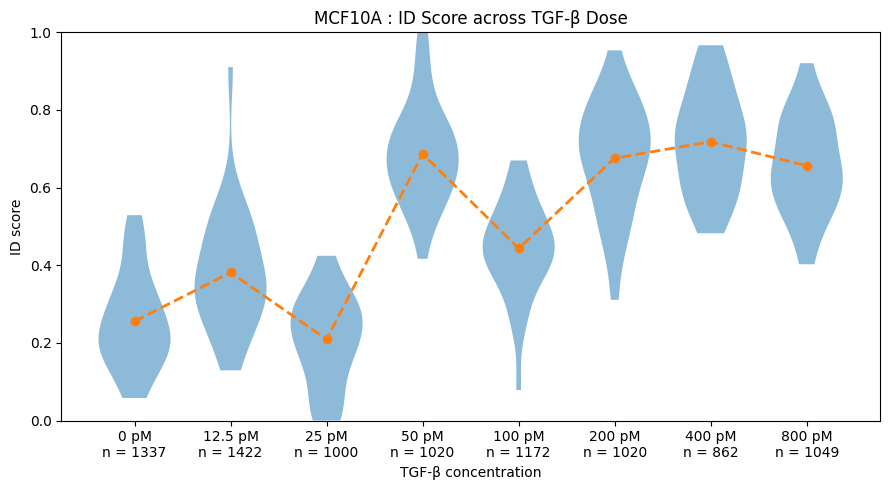

In [13]:
# ------------------------------------------------------------
# Prepare groups in dose order
# ------------------------------------------------------------

doses = sorted(id_long["Dose_pM"].unique())

id_groups = [
    id_long.loc[id_long["Dose_pM"] == dose, "ID"].values
    for dose in doses
]

id_means = [
    np.mean(group)
    for group in id_groups
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(doses))

# Violin plots
parts = ax.violinplot(
    id_groups,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Make violins slightly transparent
for body in parts["bodies"]:
    body.set_alpha(0.5)

# ------------------------------------------------------------
# Dashed line connecting mean ID scores
# ------------------------------------------------------------

ax.plot(
    positions,
    id_means,
    linestyle="--",
    marker="o",
    linewidth=2,
    markersize=6
)

# ------------------------------------------------------------
# X-axis labels: dose + number of cells
# ------------------------------------------------------------

labels = [
    f"{dose:g} pM\nn = {cell_counts.loc[dose]}"
    for dose in doses
]

ax.set_xticks(positions)
ax.set_xticklabels(labels)

# ------------------------------------------------------------
# Labels / formatting
# ------------------------------------------------------------

ax.set_xlabel("TGF-β concentration")
ax.set_ylabel("ID score")
ax.set_ylim(0, 1)

ax.set_title("MCF10A : ID Score across TGF-β Dose")

plt.tight_layout()
plt.show()

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   0.0   12.5   0.1257 0.0068  0.0213  0.2301   True
   0.0   25.0  -0.0465 0.8729 -0.1509  0.0579  False
   0.0   50.0   0.4314    0.0   0.327  0.5358   True
   0.0  100.0    0.188    0.0  0.0836  0.2924   True
   0.0  200.0   0.4204    0.0   0.316  0.5248   True
   0.0  400.0   0.4625    0.0  0.3581  0.5669   True
   0.0  800.0   0.4008    0.0  0.2964  0.5052   True
  12.5   25.0  -0.1722    0.0 -0.2766 -0.0679   True
  12.5   50.0   0.3057    0.0  0.2013  0.4101   True
  12.5  100.0   0.0622 0.6045 -0.0421  0.1666  False
  12.5  200.0   0.2947    0.0  0.1903  0.3991   True
  12.5  400.0   0.3368    0.0  0.2324  0.4412   True
  12.5  800.0   0.2751    0.0  0.1707  0.3795   True
  25.0   50.0   0.4779    0.0  0.3735  0.5823   True
  25.0  100.0   0.2345    0.0  0.1301  0.3389   True
  25.0  200.0   0.4669    0.0  0.3625  0.5713 

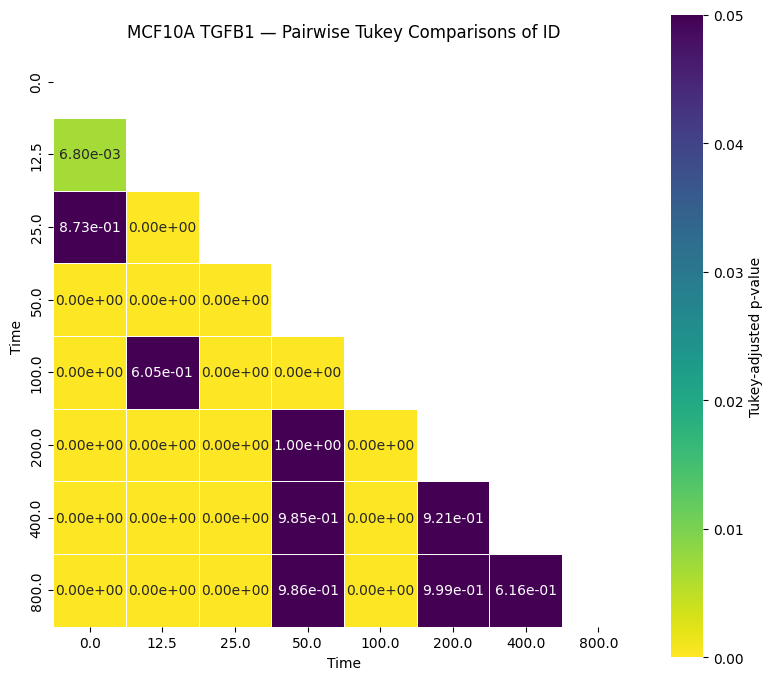

In [14]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# TUKEY TEST
# ============================================================

tukey = pairwise_tukeyhsd(
    endog=id_long["ID"],
    groups=id_long["Dose_pM"],
    alpha=0.05
)

print(tukey)


# ============================================================
# TIME ORDER
# ============================================================

doses = sorted(id_long["Dose_pM"].unique())


# ============================================================
# EXTRACT TUKEY RESULTS
# ============================================================

tukey_df = pd.DataFrame(
    data=tukey._results_table.data[1:],
    columns=tukey._results_table.data[0]
)

# Make sure p-adj is numeric
tukey_df["p-adj"] = tukey_df["p-adj"].astype(float)


# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

tukey_matrix = pd.DataFrame(
    np.nan,
    index=doses,
    columns=doses
)


for _, row in tukey_df.iterrows():

    group1 = row["group1"]
    group2 = row["group2"]
    p_adj = row["p-adj"]

    tukey_matrix.loc[group1, group2] = p_adj
    tukey_matrix.loc[group2, group1] = p_adj


# ============================================================
# HEATMAP
# LOWER TRIANGLE ONLY
# ============================================================

mask = np.triu(
    np.ones_like(tukey_matrix, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    tukey_matrix,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Tukey-adjusted p-value"
    }
)

plt.title(
    "MCF10A TGFB1 — Pairwise Tukey Comparisons of ID"
)

plt.xlabel("Time")
plt.ylabel("Time")

plt.tight_layout()
plt.show()